In [1]:
from IPython.display import HTML, display
css_file_path = "../../design/custom.css"
styles = "<link rel='stylesheet' href='%s'>" % css_file_path
display(HTML(styles))

# 4.1 $\quad$ Teoría de Tobin

## 1. Incorporacicón del *activo libre de riesgo*



- El activo libre de riesgo lo denotaremos como **$R_f$** y se caracteriza por:

    - **Retorno Garantizado**: Ofrece un retorno fijo y conocido de antemano: $\quad Retorno \   R_{f,t} = r_f = cte \ \Rightarrow \ E(R_f) = r_f$

    - **Varianza cero**: Como $r_f = cte$ la varrianza es cero: $\quad Var(r_f) =  \sigma^2_f = 0$

    - **Covarianza cero**: La covarianza del activo libre de riesgo con cualquier otro activo es cero: $\quad covar(r_f, r_i) = 0 \qquad \forall i$

    - **Ejemplos Comunes**: Bonos del gobierno de países estables, como los bonos del Tesoro de EE. UU.
 

**¿Qué ocurre cuando creas una cartera con un activo libre de riesgo y uno con riesgo?**

- Activo libre de riesgo: 
  - $E(r_f) = r_f$
  - $Var(r_f) = 0$

- Activo con riesgo:
  - $E(\tilde{r})=\mu$
  - $Var(\tilde{r})=\sigma^2$


Si creamos una cartera mixta $p$ con los pesos $w$ y $1 - w$:

  - El retorno será: 
  
  $$\boxed{r_p = w r_f + (1 - w) \mu} \tag{1}$$

  - La varianza será: 
  
  $$\sigma^2_p = w^2 \underbrace{Var(r_f)}_{\text{= 0}} + (1-w)^2 Var(\tilde{r}) + 2w(1-w)\underbrace{covar(r_f, \tilde{r})}_{\text{= 0}}$$
  $$\sigma^2_p = (1-w)^2 \sigma^2 \ \ \Rightarrow \ \boxed{\sigma_p = (1-w)\sigma} \tag{2}$$

El riesgo de la cartera sólo depende de la inversión realizada en el activo con riesgo.

Despejando $w$ y sustituyendo en el retorno esperado, tendremos que:

- El retorno de la cartera mixta será: 

**Si tenemos una rentabilidad objetivo ($r_p$)**, despejamos $w$ de la ecuación $(1)$.

$\quad \boxed{w = \frac{r_p - \mu}{r_f - \mu}}$

**Si tenemos una volatilidad objetivo ($\sigma_p$)**, despejamos $w$ de la ecuación $(2)$.

$\quad \boxed{w = 1 - \frac{\sigma_p}{\sigma}}$

- **Inversión en Activo Libre de Riesgo:**
  - Si $w = 1$: Invierte todo en activo libre de riesgo.
- **Inversión en Cartera Eficiente:**
  - Si $w = 0$: Invierte todo en la cartera eficiente.
- **Inversión Combinada:**
  - Si $0 < w < 1$: 
    - Invierte parte en activo libre de riesgo y parte en la cartera eficiente.
    - La rentabilidad y volatilidad de la nueva cartera se calculan con las fórmulas anteriores.
- **Endeudamiento e Inversión en Cartera Eficiente:**
  - Si $w < 0$: 
    - El inversor se endeuda a la tasa libre de riesgo.
    - Invierte todo en la cartera eficiente.



La incorporación del activo libre de riesgo permite:

- **Combinar posiciones en la frontera eficiente** con el activo libre de riesgo.
  
- **Posiciones Largas y Cortas**: Tomar una posición larga en el activo libre de riesgo equivale a prestar dinero sin riesgo, mientras que una posición corta es similar a pedir prestado a la tasa libre de riesgo.
  
- **Ampliación del Conjunto de Oportunidades**: Al introducir préstamo y endeudamiento a la tasa libre de riesgo, se expande el conjunto de oportunidades de inversión.
  
- **Comparación de Carteras en la Frontera Eficiente**: Interesa analizar cómo se compara una cartera en la frontera eficiente con otra que utiliza préstamo o endeudamiento para igualar el retorno esperado de otro punto en la frontera.

## 2. Ejemplos con activos reales

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import cvxpy as cp
import yfinance as yf
import seaborn as sns
#import gurobipy as gp
#from gurobipy import GRB
from scipy.interpolate import interp1d

plt.style.use('ggplot')

#### Descargamos los datos 

In [3]:
# Date range
start = '2015-01-01'
end = '2019-12-30'

# Assets todos con retornos positivos
assets = ['BA', 'BAX', 'BMY', 'CMCSA', 'CNP', 'CPB', 'DE', 'F', 'GE', 'HPQ', 
        'JCI', 'JPM','KHC', 'LUV', 'MMC', 'MO', 'NI', 'PCAR', 'PSA', 'SEE', 
        'T', 'TGT', 'TMO','TXT', 'VZ', 'ZION']

# Downloading data
prices = yf.download(assets, start = start, end = end)['Close']


[*********             19%                       ]  5 of 26 completed$SEE: Data doesn't exist for startDate = 1420088400, endDate = 1577682000
[**********************88%*****************      ]  23 of 26 completed$MMC: possibly delisted; no timezone found
[*********************100%***********************]  26 of 26 completed

2 Failed downloads:
['SEE']: Data doesn't exist for startDate = 1420088400, endDate = 1577682000
['MMC']: possibly delisted; no timezone found


In [4]:
prices = prices.loc[:, prices.isna().mean() <= 0.10]
assets = prices.columns

Elegimos el activo con ticker 'BA' y definimos la rentabilidad del activo libre de riesgo $r_f$

In [5]:
rf = 0.03 # Rentabilidad del activo libre de riesgo (anual)
ret_rf = rf / 252 # Rentabilidad del activo libre de riesgo diaria

retornos = np.log(prices.loc[:, ['BA']]).diff().dropna()

retornos['Rf'] = ret_rf

retornos.head(3)

Ticker,BA,Rf
Date,,
2015-01-05,-0.006950,0.000119
2015-01-06,-0.011848,0.000119
2015-01-07,0.015406,0.000119


Vamos a generar carteras con esos dos activos generando pesos aleatorios:

In [6]:
num_carteras = 1000
num_act = 2

#genero pesos 
pesos_w1 = np.linspace(-1, 1, 200)
pesos = np.column_stack((1 - pesos_w1, pesos_w1))
pesos.shape

(200, 2)

In [7]:
#calculo retornos y volatilidades
ret_carteras = retornos @ pesos.T

volatilidades = np.sqrt(np.var(ret_carteras, axis=0)*252)
rentabilidades = 252*np.mean(ret_carteras, axis=0)

In [8]:
# Veamos los retornos anualizados de los activos

retornos.mean()*252

Ticker
BA    0.212925
Rf    0.030000
dtype: float64

In [9]:
# Veamos las desviaciones anualizadas de los activos

retornos.std()*np.sqrt(252)

Ticker
BA    2.527444e-01
Rf    6.456764e-19
dtype: float64

In [10]:

def pinta_lineal(rf, r, std, hline=None, vline=None, nueva_figura=True, tag=None):

    if nueva_figura:
        plt.figure(figsize=(10, 6))

    # Individual assets
    plt.scatter(volatilidades, rentabilidades, color='blue', s=50, alpha=0.7)

    # Annualized risk-free asset and risky portfolio
    rf_anual = rf * 252
    r_anual = r * 252
    std_anual = std * np.sqrt(252)

    plt.scatter(0, rf_anual, color='red', s=150, label='Risk-free asset')
    plt.text(0, rf_anual + 0.02, r'$R_f$', color='red', fontsize=14)

    if tag is not None:
        # Risky asset
        plt.scatter(std_anual, r_anual, color='green', s=150)
        plt.text(std_anual, r_anual, tag, color='green', fontsize=14)

        # Lending and borrowing regions
        plt.plot([0, std_anual], [rf_anual, rf_anual],
                 'k--', linewidth=1)

        plt.plot([std_anual, 2*std_anual], [rf_anual, rf_anual],
                 'k--', linewidth=1)

        plt.text(std_anual/2, rf_anual + 0.01,
                 'Lending at Rf', ha='center')

        plt.text(1.5*std_anual, rf_anual + 0.01,
                 'Borrowing at Rf', ha='center')

        plt.vlines(std_anual, rf_anual, r_anual, color='green')

    if hline is not None:
        plt.axhline(hline, color='black')

    if vline is not None:
        plt.axvline(vline, color='black')

    plt.title('Portfolio with a Risk-Free Asset')
    plt.xlabel('Annualized Volatility')
    plt.ylabel('Annualized Expected Return')
    plt.grid(True, linestyle='--', alpha=0.5)


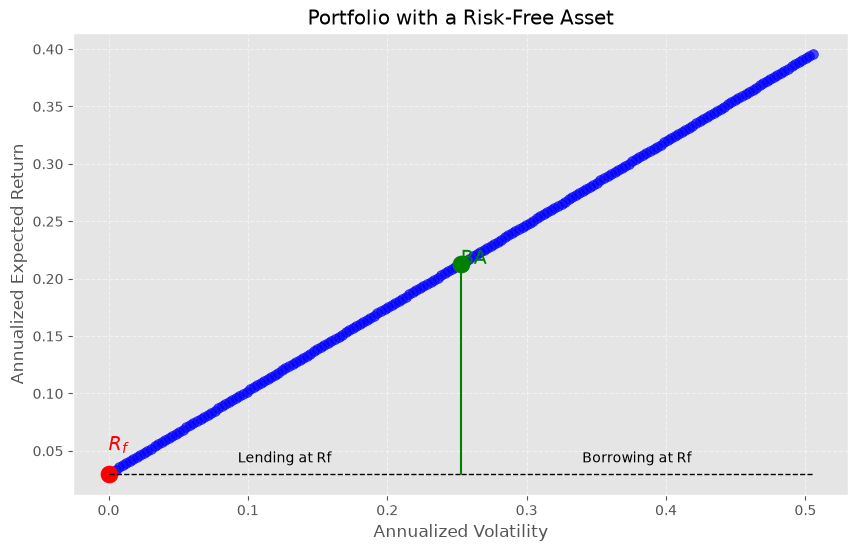

In [11]:
pinta_lineal(ret_rf, retornos["BA"].mean(), retornos["BA"].std(), tag="BA")

### EJERCICIO:

Calcula la cartera formada por los dos activos anteriores y que tenga:

 a) una rentabilidad del 14% anual

 b) una rentabilidad del 25% anual
 
 c) una volatilidad del 7% anual

**APARTADO A:**

In [12]:
rf = ret_rf*252  # Activo libre de riesgo
r = 0.2129       # Activo con riesgo
re = 0.14        # Rentabilidad objetivo

w = (re - r) / (rf - r)
w

0.39857845817386545

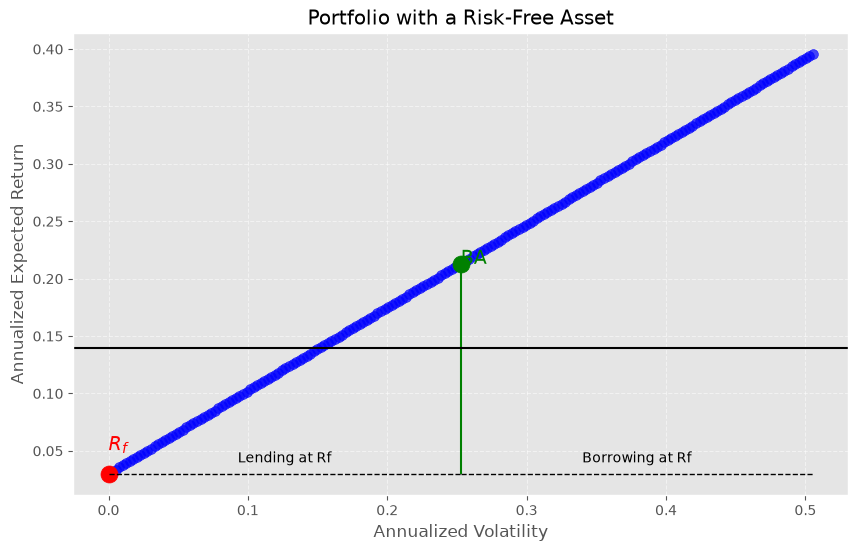

In [13]:
pinta_lineal(ret_rf, retornos["BA"].mean(), retornos["BA"].std(), hline=re, tag="BA")

**APARTADO B:**

In [14]:
rf = ret_rf * 252
r = 0.2129
re = 0.25

w = (re - r) / (rf - r)
w

-0.20284308365226897

¿Qué quiere decir este valor de $w$?

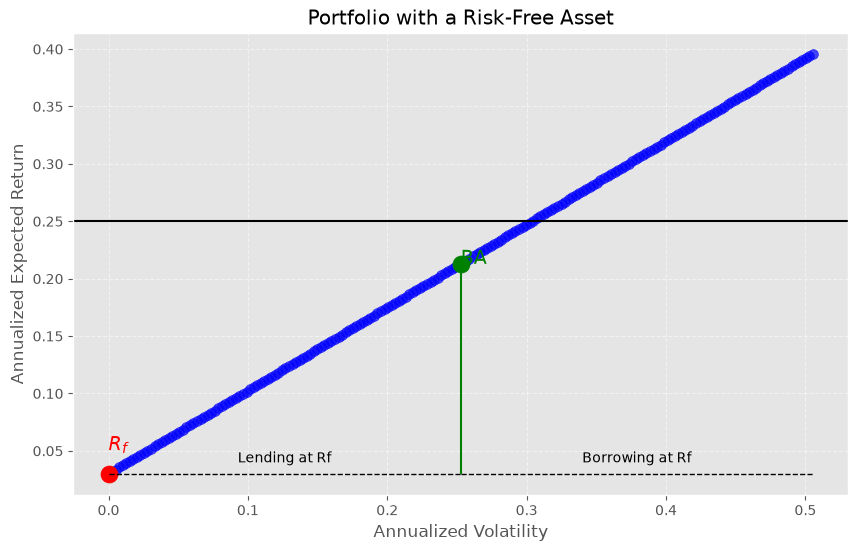

In [15]:
pinta_lineal(ret_rf, retornos["BA"].mean(), retornos["BA"].std(), hline=re, tag="BA")

**APARTADO C:**

In [16]:
std = 0.2527
stde = 0.07

w = 1 - stde / std
w

0.7229916897506925

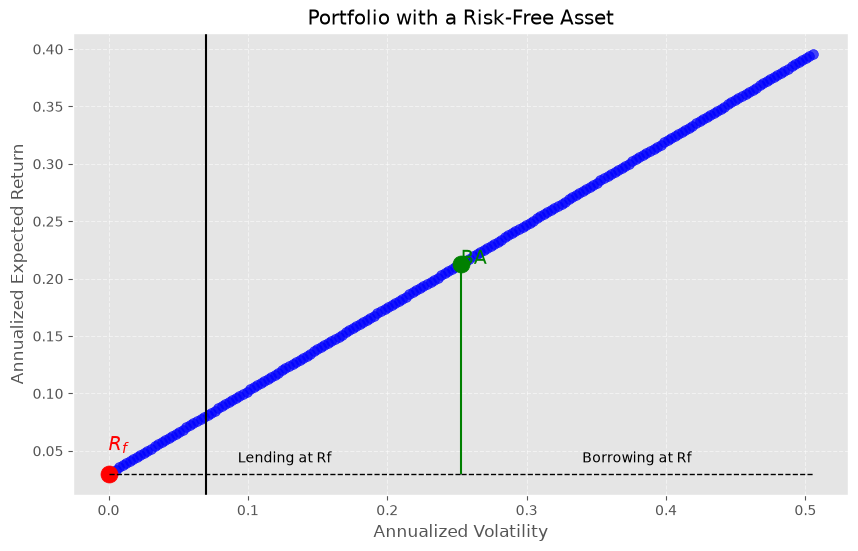

In [17]:
pinta_lineal(ret_rf, retornos["BA"].mean(), retornos["BA"].std(), vline=stde, tag="BA")

## 3. Combinaciones activo libre de riesgo con el resto de los activos

In [18]:
retornos = np.log(prices).diff().dropna()

num_act = len(assets)

In [19]:
#Calculamos la matriz de covarianzas y los retornos esperados
matriz_cov = retornos.cov().to_numpy() # Covariance matrix
retornos_esperados = retornos.mean().to_numpy() # Column vector expected return

Primero calculamos la cartera de mínimo riesgo

In [20]:
#Variables de decisión
pesos = cp.Variable(num_act)

#Restricciones
constraints = [pesos >= 0,  # No shorting
               cp.sum(pesos) == 1, # Fully invested
               ]

#Función Objetivo
riesgo = cp.quad_form(pesos, matriz_cov) # Riesgo de la cartera
objective = cp.Minimize(riesgo) # Minimizar la varianza

ret = retornos_esperados.T @ pesos # Retorno esperado de la cartera

#Problema y resuelvo
prob = cp.Problem(objective, constraints)
resultado = prob.solve()

#Guardamos los valores de la rentabilidad y riesgo de la cartera de mínimo riesgo
min_riesgo = np.array([np.sqrt(riesgo.value), ret.value])

Definimos los distintos valores de riesgo para calcular la frontera eficiente:

- Riesgo mínimo: El de la cartera de mínimo riesgo

- Riesgo máximo: El del activo de máxima rentabilidad

In [21]:
imax = np.argmax(retornos.mean(axis=0))
riesgos_lst = np.linspace(min_riesgo[0], np.sqrt(matriz_cov[imax, imax]), num=500)

Calculamos la cartera de mayor rentabilidad para cada uno de los riesgos anteriores.

In [22]:
retornos_lst = []
pesos_lst = []

for risk in riesgos_lst:
 #Variables de decisión
    pesos = cp.Variable(num_act)

    # Función objetivo
    rentabilidad = cp.Maximize(retornos_esperados.T @ pesos)

    #Restricciones
    riesgo = cp.quad_form(pesos, matriz_cov)

    constraints = [pesos >= 0,
                    cp.sum(pesos) == 1,
                    riesgo <= risk**2
                    ]

    prob = cp.Problem(rentabilidad, constraints)
    resultado = prob.solve()
    #resultado = prob.solve(solver=cp.MOSEK)
    retornos_lst.append(rentabilidad.value)
    pesos_lst.append(pesos.value)

In [23]:
def pinta_frontera():
    plt.figure(figsize=(12, 6))

    #Desplazamientos para las etiquetas
    desplazamiento_x = 0.001  # Ajusta este valor según sea necesario
    desplazamiento_y = 0.005  # Ajusta este valor según sea necesario



    plt.scatter(np.sqrt(252)*min_riesgo[0], 252*min_riesgo[1], c='red', marker='x', s=50, alpha=0.7)
    plt.text(np.sqrt(252)*min_riesgo[0]+ 3*desplazamiento_x, 252*min_riesgo[1] +  2*desplazamiento_y , 'Min riesgo', fontsize=13, color='red')

    # Puntos de cada activo
    plt.scatter(np.sqrt(np.diag(matriz_cov)*252),252* retornos_esperados, color='blue', s=50, alpha=0.7)
    plt.plot(np.sqrt(252)*riesgos_lst, 252*np.array(retornos_lst), '-', color='green', label='Frontera Eficiente', alpha=0.5)


    # Añadiendo los nombres de los activos con un desplazamiento


    for i, asset in enumerate(assets):
        plt.text(np.sqrt(matriz_cov[i, i]*252) + desplazamiento_x, 252*retornos_esperados[i]+desplazamiento_y , asset, fontsize=9)
    plt.xlabel('Volatilidad')
    plt.ylabel('Rentabilidad')
    plt.title('Activos y frontera eficiente')
    #plt.colorbar(label='Sharpe ratio')



    # Configurar el borde de la figura
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

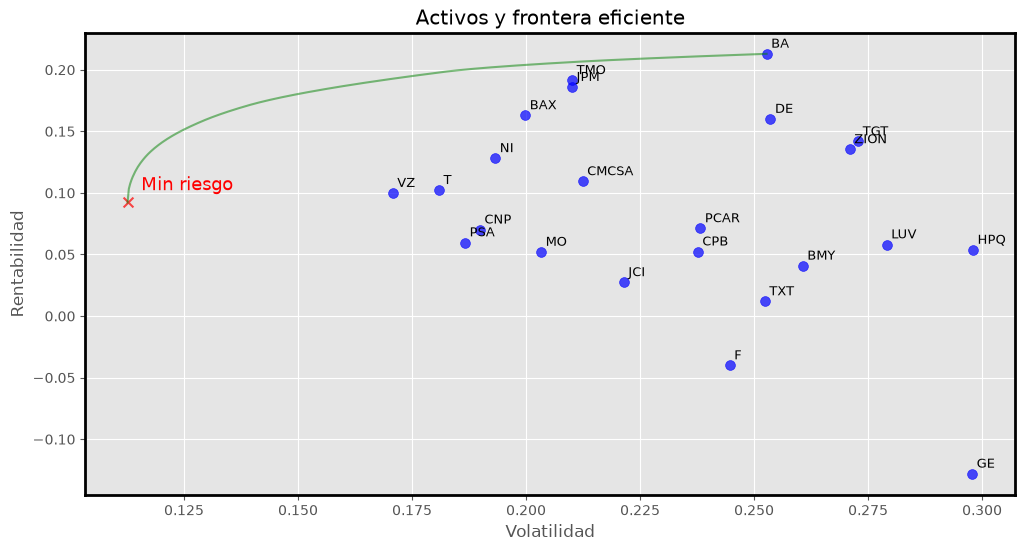

In [24]:
pinta_frontera()

Analicemos ahora el efecto de introducir:

- Activo libre de riesgo

- Posibilidad de financiarse o endeudarse con el activo libre de riesgo


Como hemos visto en el capítulo anterior (Markowitz) las únicas carteras que tiene sentido emplear son las de la frontera eficiente. Para comenzar, vamos a elegir la cartera de mínimo riesgo y generamos **carteras mixtas formadas por el activo libre de riesgo y la cartera de mínimo riesgo**. Hemos visto que las carteras formadas formarán una recta que pasa por los dos activos.

In [25]:
def pinta_carteras_con_rf(rf, r, std, tag=None):
    pinta_frontera()
    pinta_lineal(rf, r, std, nueva_figura=False, tag=tag)

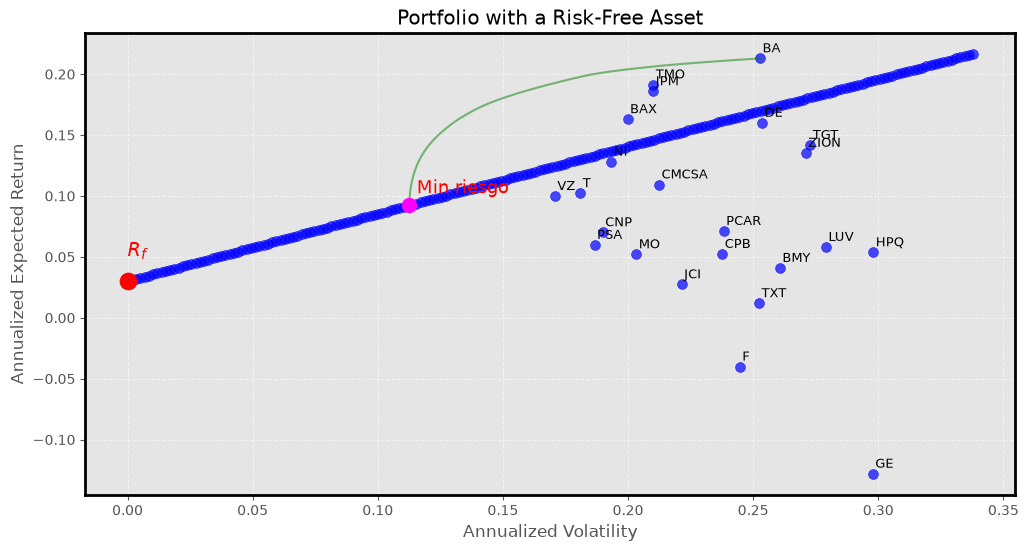

In [26]:
pesos_w1 = np.linspace(-2, 1, 200)
volatilidades = []
rentabilidades = []
for w1 in pesos_w1:
    w2 = 1 - w1
    volatilidades.append((w2 * min_riesgo[0]) * np.sqrt(252))
    rentabilidades.append((ret_rf * w1 + min_riesgo[1] * w2)*252)

pinta_carteras_con_rf(ret_rf, min_riesgo[1], min_riesgo[0])
plt.plot(min_riesgo[0]*np.sqrt(252), min_riesgo[1]*252, '.', markersize=20, color="magenta")

Puedo elegir otra cartera de la frontera eficiente y generar carteras mixtas con el activo libre de riesgo.

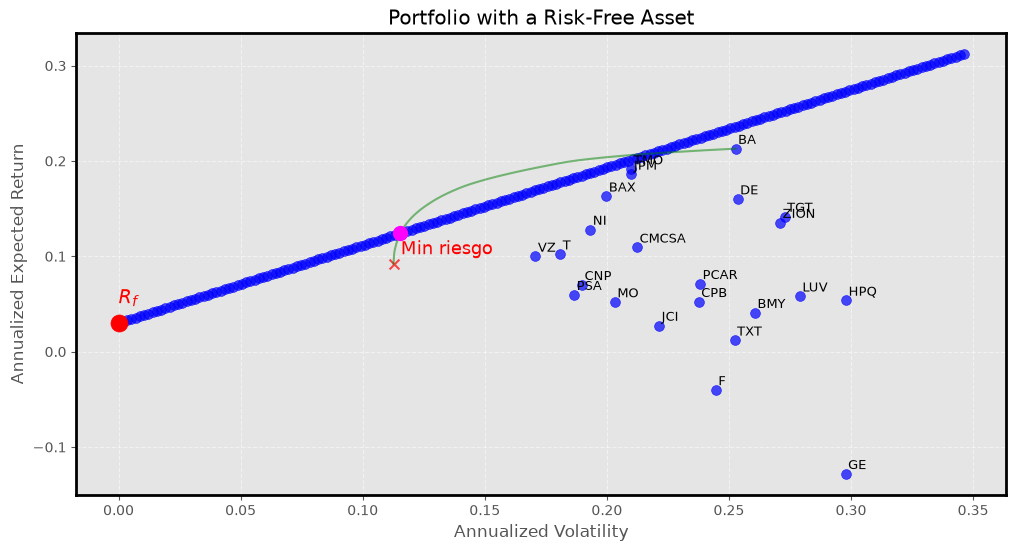

In [27]:
punto_act1 = [riesgos_lst[10], retornos_lst[10]]

pesos_w1 = np.linspace(-2, 1, 200)
volatilidades = []
rentabilidades = []
for w1 in pesos_w1:
    w2 = 1 - w1
    rentabilidades.append((ret_rf * w1 + punto_act1[1] * w2)*252)
    volatilidades.append((w2 * punto_act1[0]) * np.sqrt(252))

pinta_carteras_con_rf(ret_rf, punto_act1[1], punto_act1[0])
plt.plot(punto_act1[0]*np.sqrt(252), punto_act1[1]*252, '.', markersize=20, color="magenta")

Veamos las rectas para varias carteras de la frontera eficiente:

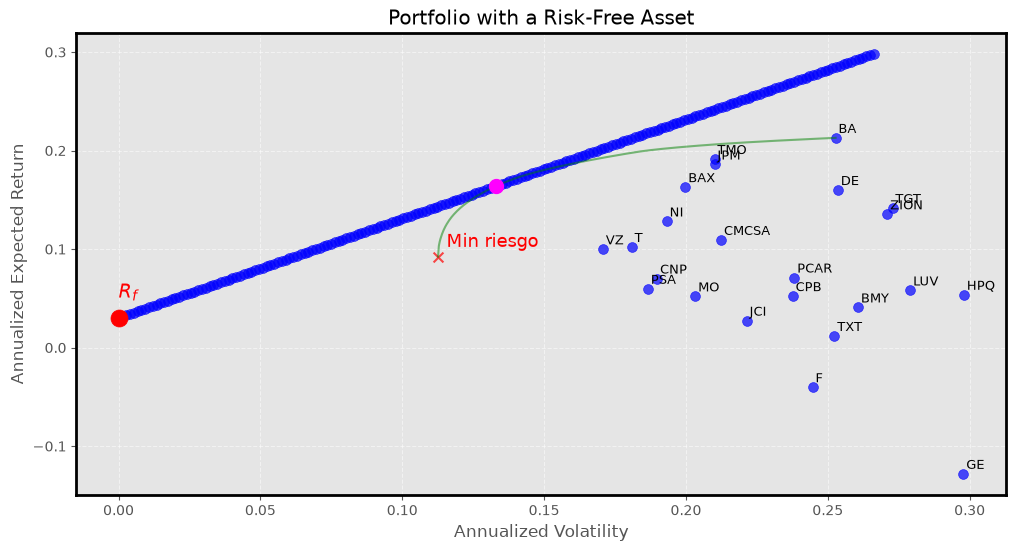

In [28]:
punto_act1 = [riesgos_lst[73], retornos_lst[73]]

pesos_w1 = np.linspace(-1, 1, 200)
volatilidades = []
rentabilidades = []
for w1 in pesos_w1:
    w2 = 1 - w1
    rentabilidades.append((ret_rf * w1 + punto_act1[1] * w2)*252)
    volatilidades.append((w2 * punto_act1[0]) * np.sqrt(252))

pinta_carteras_con_rf(ret_rf, punto_act1[1], punto_act1[0])
plt.plot(punto_act1[0]*np.sqrt(252), punto_act1[1]*252, '.', markersize=20, color="magenta")

## 4. Linea del mercado de capitales 

Vamos a determinar formalmente la **Línea del Mercado de Capilates (LMC)**:

Para ello, analizamos la estructura de la frontera eficiente cuando introducimos el activo libre de riesgo:

$$\begin{gather}
max \text{   } w_0r_f+\mu^T w-\lambda w^T\Sigma w \tag{1}\\
s.t. \text{   } w_0+w=1 \nonumber
\end{gather}$$

siendo:

- $w_0$ la inversión en el activo libre de riesgo,

- $w$ la inversión en el activo con riesgo,

- $r_f$ es la rentabilidad del activo libre de riesgo,

- $\mu$ es la rentabilidad esperada del activo con riesgo,

- $\lambda$ es el coeficiente de aversión al riesgo del inversor

- $\Sigma$ la matriz de covarianzas.


La ecuación anterior se puede reescribir como un problema sin restricciones eliminando $w_0$, para ello:

- despejamos $w_0$ de la restricción
- sutituimos en la función objetivo
- simplificamos y rescribimos
  
$$\max \text{   } w^T\pi - \lambda w^T\Sigma \tag{2}w$$

donde $\pi=\mu-R_f$ es el vector de la prima por riesgo. 

Aplicamos la condición de primer orden (derivamos e igualamos a 0):

$$\pi-2\lambda\Sigma w=0 \tag{3}$$

Resolviendo obtenemos las ponderaciones una cartera mixta eficiente:

$$
w^*=
\underbrace{\frac{1}{2\lambda}}_{\text{Exposición al riesgo}}
\;\underbrace{\Sigma^{-1}\pi}_{\text{Composición de la cartera}}
$$

$$w_0^*=1-w^{*T} \quad \Rightarrow w_0^*=1-\frac{1}{2\lambda}i^T\Sigma^{-1}\pi$$

Observamos que cuando $\lambda \rightarrow +\infty$ la totalidad de la inversión se destina al activo libre de riesgo.

El coeficiente $\lambda$ determina el peso del activo libre de riesgo en la cartera.

## 5. Teoría separación Tobin

Hasta ahora hemos realizado:

- **Cálculo de Carteras Eficientes para un Inversor:** Se ha considerado la función de utilidad del inversor, enfocándose en la tolerancia al riesgo y la rentabilidad esperada.

- **Introducción del Activo Libre de Riesgo:** Al introducir un activo libre de riesgo, se observa que la cartera que importa de la frontera eficiente es la cartera tangente.

- **Cartera Tangente en la Frontera Eficiente:** La cartera tangente es la misma para cualquier inversor, independientemente de su función de utilidad.

- **Selección de Cartera en la Línea de Mercado de Capitales:** Cualquier inversor seleccionará una cartera de la Línea de Mercado de Capitales (LMC).

La **teoría de separación de Tobin** dice que la selección de cartera se divide en **dos fases**:

1- Identificación de la **cartera tangente**.

2- Cada inversor particular elige su posición en la LMC según su aversión al riesgo.

Esta afirmación lleva implícito las siguientes hipótesis:

- Los inversores optimizan el binomio rentabilidad riesgo.
- Comparten la misma estimación de premio por riesgo, volatilidad y correlaciones. Eso implica que tienen acceso a la misma información sin coste.

### Cálculo de la cartera tangente

En la figura anterior vemos que las carteras eficientes son las **carteras mixtas** que están en la recta tangente que pasa por $r_f$.

La recta tangente es, de las rectas posibles, la que tiene máxima pendiente.

En la figura de abajo, podemos ver que la pendiente es el $\text{Ratio de Sharpe} = \Large \frac{r_p - r_f}{\sigma_p}$

Luego tenemos que calcular la **cartera con máximo ratio de sharpe**.

<img src="../imgs/sharpe.PNG"  alt="drawing" width="400"/>

### Maximizar el ratio de sharpe

Lo vamos a resolver de dos maneras:

-  Primero lo resolvemos de manera analítica

- Luego lo resolvemos usando la libería cvxpy en python

## 1)  Cálculo del máximo ratio de sharpe:

Se trata de resolver:

$$\begin{gather}
max\text{  }\frac{\sum_i(\mu_i-r_f)w_i}{\sqrt{w^T\Sigma w}}=\frac{\pi^Tw}{\sqrt{w^T\Sigma w}}=S_p(w) \\ 
s.t. \sum_i w_i=1 \nonumber
\end{gather}$$

### Cálculo del máximo ratio de sharpe con CVXPY

Si intentas maximizar directamente el ratio de sharpe, da un error DCP ya que no es una función convexa.

In [29]:
pesos = cp.Variable(num_act)

riesgo = cp.quad_form(pesos, matriz_cov)
pi = retornos_esperados - ret_rf
rentabilidad = pi @ pesos

# Restricciones
constraints = [pesos >= 0,
               cp.sum(pesos) == 1, 
              ]

objetivo = cp.Maximize(rentabilidad/riesgo)

prob = cp.Problem(objetivo, constraints)

resultado = prob.solve()

DCPError: Problem does not follow DCP rules. Specifically:
The objective is not DCP. Its following subexpressions are not:
[ 7.25890877e-04  5.27592358e-04  4.29528908e-05  3.14786066e-04
  1.59151253e-04  8.84898581e-05  5.15956700e-04 -2.78323379e-04
 -6.27443208e-04  9.39920012e-05 -1.04654731e-05  6.18658022e-04
  1.11426619e-04  8.74080010e-05  3.89246107e-04  1.63313451e-04
  1.17907938e-04  2.86524798e-04  4.43402203e-04  6.40635789e-04
 -7.19588256e-05  2.77146470e-04  4.18011441e-04] @ var28533 / QuadForm(var28533, [[0.00 0.00 ... 0.00 0.00]
 [0.00 0.00 ... 0.00 0.00]
 ...
 [0.00 0.00 ... 0.00 0.00]
 [0.00 0.00 ... 0.00 0.00]])

El **ratio de sharpe**  se define como:

$\qquad \qquad \text{Ratio de Sharpe} = \Large \frac{r_p - r_f}{\sigma_p}$

Donde:
- $ r_p $ es el retorno esperado de la cartera.
- $ r_f $ es la tasa de retorno libre de riesgo.
- $ \sigma_p = \sqrt{\sigma^2_p}$ es la desviación estándar de los retornos de la cartera, que representa el riesgo.

### Por qué el Ratio de Sharpe no es una función convexa

La naturaleza no convexa del *ratio de Sharpe* se debe a las características de su formulación matemática:

- **Forma de la Función**: El ratio de Sharpe  es una fracción con el riesgo (una raíz cuadrada) en el denominador.

- **Desviación Estándar (Riesgo)**: La desviación estándar, $\sigma_p$, es una función cóncava porque es la raíz cuadrada de la varianza (que es una suma de cuadrados).
En matemáticas, la raíz cuadrada de una función cuadrática no es convexa.

- **División por una Función Cóncava**: Dividir una función lineal (el exceso de retorno) por una función cóncava (la desviación estándar) resulta en una función que no es necesariamente convexa. Las operaciones que involucran la división por funciones cóncavas no preservan la convexidad.

- **Violación de la Desigualdad de Jensen**: Una propiedad clave de las funciones convexas es que deben cumplir la desigualdad de Jensen. El ratio de Sharpe no cumple con esta desigualdad debido a su denominador cóncavo.

En resumen, la combinación de una función lineal en el numerador y una función cóncava en el denominador es lo que hace que el ratio de Sharpe no sea convexo. Esto tiene implicaciones importantes en optimización, ya que los métodos estándar para optimizar funciones convexas no pueden aplicarse directamente para maximizar el ratio de Sharpe.

- **Transformación del Problema:**
  
  - Utilizar la propiedad de homogeneidad de grado 1 de la función objetivo $f$, que establece $f(\alpha x) = \alpha f(x)$ para $\alpha \in \mathbb{R}_{++}$.
  - Introducir un factor de escala $\alpha$ para reformular el problema original con la variable $x = \alpha w$, de manera que el numerador sea igual a $1$, es decir, el problema pase a ser: $$\qquad \qquad max\text{  }\frac{\pi^Tw}{\sqrt{w^T\Sigma w}} \quad  \Rightarrow \quad \max \frac{1}{\sqrt{x^T \Sigma x}}$$ 

  
  - Al quedar de esa manera, el problema se puede expresar como:
 $$min\text{ }x^T\Sigma x $$
  - Las restricciones pasan a ser:
      - $\pi^T x = 1$: esto es lo que hace que el numerador sea 1
      - $x \geq 0$:    equivalente a que no haya posiciones cortas


- **Solución del Problema Reformulado:**
  - El problema reformulado es equivalente a un programa cuadrático convexo, facilitando la identificación de una solución óptima $x^*$.

- **Recuperación de la Solución Inicial:**
  - La solución al problema original $w^*$ se recupera normalizando las $x^*$ para que la suma sea $1$.
  
Este enfoque aprovecha las propiedades matemáticas específicas de la función objetivo para simplificar y resolver eficientemente problemas de optimización.



In [ ]:
# Variable de decisión (pesos del portafolio)
x = cp.Variable(num_act)
# Riesgo (desviación estándar) del portafolio
riesgo = cp.quad_form(x, matriz_cov)

#Cálculo de pi como retornos esperados menos la rantabilidad del activo libre de riesgo
pi = retornos_esperados - ret_rf

#Restricciones
constraints = [pi @ x ==1, # para que el numerador sea 1
               x>=0]       # sin posiciones cortas

objective = cp.Minimize(riesgo) # Minimizo el riesgo

# Problema de optimización
problema = cp.Problem(objective, constraints)        

# Resolver el problema
resultado  = problema.solve(solver=cp.ECOS)

In [ ]:
# Normalizo los pesos
pesos = x.value
pesos /= pesos.sum()

pesos_df = pd.DataFrame(pesos, index=assets)

CVXPY resuelve el problema de manera numérica. Esto hace que haya pesos con valores muy pequeños, en el caso anterior hay pesos con valores de $10^{-9}$, que los podemos poner a cero.

In [ ]:
#ponemos a 0 los pesos menores de 10**-4 y elegimos los activos con pesos mayores a 0

pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0  for x in pesos_df[0]])
activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

In [ ]:
# Calculamos la rentabilidad y volatilidad de la cartera de máximo ratio de sharpe

retorno_cart_sharpe = np.dot(retornos_esperados, pesos_ajustados)*252
std_sharpe = np.sqrt(pesos_ajustados @ matriz_cov @ pesos_ajustados.T)*np.sqrt(252)

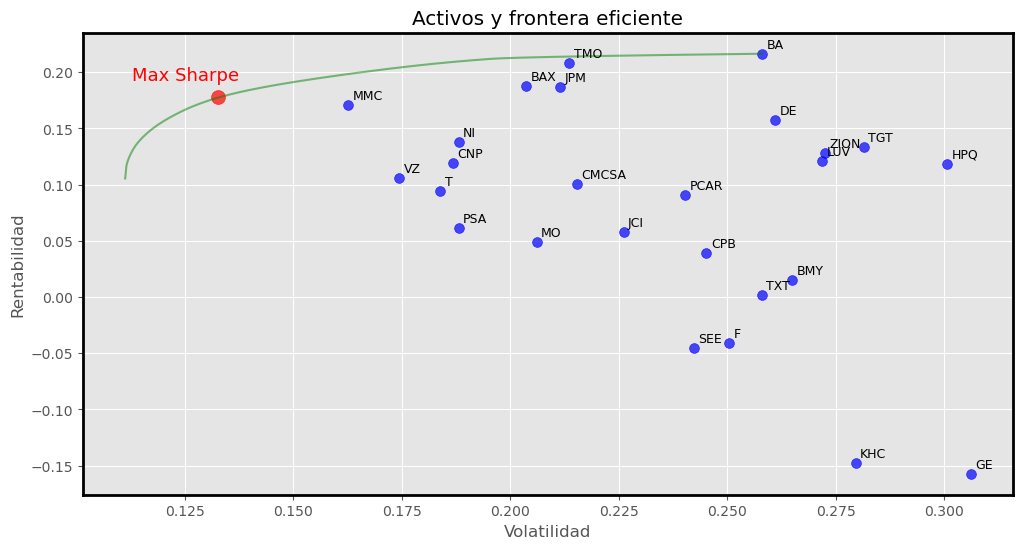

In [ ]:
#grafico

plt.figure(figsize=(12, 6))

#Desplazamientos para las etiquetas
desplazamiento_x = 0.001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.005  # Ajusta este valor según sea necesario



#plt.scatter(cartera_sharpe_max[0], 252 * cartera_sharpe_max[1], c='red', marker='o', s=100, alpha=0.7)
plt.text(std_sharpe - 20* desplazamiento_x, retorno_cart_sharpe+3*desplazamiento_y , 'Max Sharpe', fontsize=13, color='red')
plt.scatter(std_sharpe, retorno_cart_sharpe, c='red', marker='o', s=100, alpha=0.7)

# plt.scatter(np.sqrt(252*min_riesgo[0]), 252*min_riesgo[1], c='red', marker='x', s=50, alpha=0.7)
# plt.text(np.sqrt(252*min_riesgo[0])+ 3*desplazamiento_x, 252*min_riesgo[1] +  2*desplazamiento_y , 'Min riesgo', fontsize=13, color='red')

# Puntos de cada activo
plt.scatter(np.sqrt(np.diag(matriz_cov)*252),252* retornos_esperados, color='blue', s=50, alpha=0.7)
plt.plot(np.sqrt(252)*riesgos_lst, 252*np.array(retornos_lst), '-', color='green', label='Frontera Eficiente', alpha=0.5)


# Añadiendo los nombres de los activos con un desplazamiento


for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]*252) + desplazamiento_x, 252*retornos_esperados[i]+desplazamiento_y , asset, fontsize=9)
plt.xlabel('Volatilidad')
plt.ylabel('Rentabilidad')
plt.title('Activos y frontera eficiente')
#plt.colorbar(label='Sharpe ratio')



# Configurar el borde de la figura
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)


plt.show()

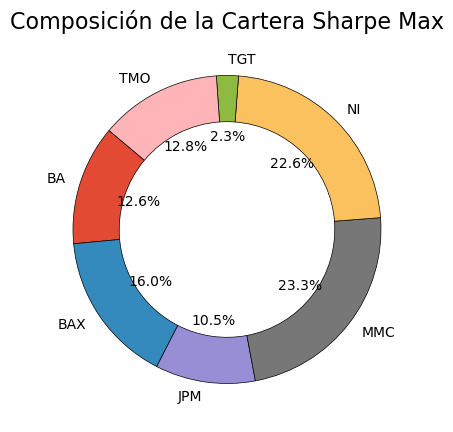

In [ ]:
# Crear el gráfico de donut
plt.figure(figsize=(5, 5))

plt.pie(pesos_filtrados, labels=activos_filtrados, autopct='%1.1f%%', startangle=140, wedgeprops={'width': 0.3, 'edgecolor': 'black'})

# Añadir título
plt.title('Composición de la Cartera Sharpe Max', fontsize=16)

# Mostrar el gráfico
plt.show()

### EJERCICIO

Tu asesor financiero te ha sugerido que el universo de activos en los que invertir son los de la lista assets que hemos estado usando en este notebook, más el actvo libre de riesgo que da una rentabilidad anual igual a ret_rf. Has decidido que, para poder pagar todos tus gastos,  necesitas sacar una rentabilidad del 10% anual. Calcula la cartera que formarías.

In [ ]:
# Variable de decisión (pesos del portafolio)
r_esperado = 0.1

In [ ]:
print(f' Sabemos que  la rentabilidad y volatilidad de de la cartera de máximo ratio de sharpe son: {retorno_cart_sharpe:.2f} , {std_sharpe:.2f}')

 Sabemos que  la rentabilidad y volatilidad de de la cartera de máximo ratio de sharpe son: 0.18 , 0.13


Usando la fórmula de la rentabilidad de una cartera mixta, calculamos la inversión en el activo libre de riesgo:

$$\quad \boxed{w = \frac{r_p - \mu}{r_f - \mu}}$$

In [ ]:
w = (r_esperado- retorno_cart_sharpe)/(ret_rf*252 - retorno_cart_sharpe)
w

0.5255027452077843

In [ ]:
rentabilidad_cartera = w*ret_rf*252 + (1-w)*retorno_cart_sharpe
volatilidad_cartera = np.sqrt((w*0)**2 + (1-w)**2 * std_sharpe**2)

print(f' La rentabilidad y volatilidad de la cartera con rentabilidad esperada del 10% son: {rentabilidad_cartera:.2f} , {volatilidad_cartera:.2f}')

 La rentabilidad y volatilidad de la cartera con rentabilidad esperada del 10% son: 0.10 , 0.06
